# Train one HGT network with hierarchical skill family/direction and auxiliary intent

Run **26_prepare_skill_intent_target_relative_missile_nn_duel_skill_forecasting.ipynb**
first. This is the **single-seed, auxiliary-intent counterpart to notebook 25**.
Run All fits **one hierarchical network with seed 42**, selects its checkpoint using skill test
NLL, then saves skill and intent predictions, baselines and diagnostics.

The network retains notebook 25's HGT-v2 encoder: two width-64 graph layers with
four heads; separately gated aircraft/ownership/targeting families; 18 physical
edge features; and the learnable distance/CPA/bearing/energy threat prior.
The temporal Transformer remains width 96, six heads, two layers, dropout 0.25.
Inputs are unchanged 51-frame histories (115 channels for the full catalogue).
Missile positions and velocities are relative to their targets. Both aircraft's
backward accelerations and current own-skill indicators remain available.

The skill readout first predicts **29 families**, then **left/right conditioned on
each of the four mirrored families**. The 25 singleton families need no direction.
These distributions reconstruct probabilities for the original 33 skills:
`P(skill) = P(family) * P(direction | family)` for mirrored skills, or just
`P(family)` for singletons. The default prediction is the largest **joint skill
probability**, preserving the original evaluation task. Optional greedy decoding
can instead select the family first and then its direction.

An auxiliary MLP predicts **offensive, defensive, context_dependent** at each +1/+2/+5s
horizon, alongside the hierarchical skill readout. The three groups are frozen in the
prepared dataset, with 9/11/13 catalogue entries. Generic manoeuvres retain a
context-dependent label rather than being assigned an unobserved intent.
**Family-first partial-credit loss:** reward the correct family even when the side
is wrong, and add a bonus for the correct side. Defaults are `family_reward=1`
and `handedness_reward=1`. For a true mirrored skill,

`C = (a * P(true_family) + b * P(true_family, true_side)) / (a + b)`.

For a singleton, `C = P(true_family)`. The unweighted skill loss is `-log C`. To compensate for imbalance, training uses
`L = w_family * (CE_family + w_hand * side_penalty) + 0.25 * intent_CE + 1e-6 * L1`,
where `side_penalty = log(a+b) - log(a + b*P(true_side|true_family))` for mirrored
labels and zero for singleton labels. Both components are averaged over all valid
skill labels within each horizon, then over represented horizons. In the unweighted base scoring, the hard-decision
limit is: correct family+side gets normalized credit 1, correct family with wrong side
gets 0.5, and a wrong family gets 0. Side correctness never earns a bonus without
the correct family. Non-directional skills have no side penalty or fake bonus.
Family-frequency weights are shared by left and right, while handedness weights
correct imbalance **within each mirrored family and each horizon**. They are fitted
only on retained training labels. The default is capped inverse-square-root support
with maximum rare/common ratio 5 and frequency-weighted mean one per pair/horizon.
Thus imbalance between sides is corrected once, in the handedness penalty, rather
than again in a global leaf-class weight. Counts and weights are audited and saved.
All heads share the encoder, so auxiliary supervision reaches the graph and
temporal layers. Future skill/intent labels are never encoder inputs.

The grouped 40/30/30 partitions, training-only scaling, non-overlapping training
histories and missing-label masks come from the base dataset without alteration.
Training retains AdamW, 5% learning-rate warm-up and cosine decay, class-weighted
skill CE, L1, and stopping checks after epoch 20. The skill head's **unweighted test
NLL alone selects checkpoints**; validation is evaluated only after training ends.
These are initial settings, not evidence of improvement over notebook 25.

The intent head is evaluated against both an intent training-frequency baseline
and probabilities obtained by grouping the trained skill head. This reveals
whether the separate head adds anything beyond the existing skill predictions.
One seed cannot estimate variability across independent fits.

Run All trains once and writes `best.pt`, resumable `last.pt`, both sets of final
prediction NPZs, metric CSVs and diagnostic PNGs. Install `.[ml]` and a Jupyter/
IPython kernel. CPU uses FP32; CUDA can use BF16 training with FP32 graph reductions
and FP32/math evaluation. Every code cell is timed.

Artifacts use `artifacts/nn_duel_skill_intent_forecasting/`, with a singular
`comparisons/latest_hgt_hierarchical_intent_run.json` receipt. Set `BVR_NN_INTENT_DATA` to override
the prepared data directory or `BVR_NN_INTENT_MLFLOW=0` to disable optional tracking.
For resume/report-only execution, supply the one `EXISTING_RUN` path. Source, data,
taxonomy and config checks protect reuse. Start fresh runs for this architecture;
earlier flat-head checkpoints have a different skill readout.

Notebook 26 must provide the new **v2 label overlay**, including the frozen family/
direction mapping. Re-run notebook 26 to refresh an earlier intent-only overlay;
no new base features, scaling or scenario splits are required. Family metrics and
conditional-direction metrics are saved separately. Direction reports condition
on the true paired family; they are not end-to-end original-skill accuracy.

The reward is optimized through smooth probabilities, not through a hard argmax
or reinforcement-learning update. For the default rewards the unweighted extra handedness
penalty is bounded by `log(2)`; its fitted side weight is capped at 5, so the balanced
side term remains bounded by `5*log(2)` rather than introducing an unbounded side
cross-entropy penalty. The joint 33-skill NLL is still reported and selects checkpoints, but
it is no longer the skill training objective. `family_reward` controls base family
credit and `handedness_reward` the additional side bonus; setting the latter to zero
trains the family task only. Existing notebook-26 v2 labels remain suitable; start
fresh notebook-27 runs with the new objective. No re-preparation is needed.

The base reward metrics retain the unweighted half-credit/full-credit definition
for comparable reporting. The training penalty for a rare side is larger than for
its common mirror. `handedness_weighting` supports `sqrt_inverse` (default),
`inverse`, or `none`; `max_handedness_weight_ratio` controls the cap. Empty sides
and families remain in the outputs and are reported explicitly; absent training
support cannot be repaired by weighting alone. Existing notebook-26 data is valid;
start fresh training runs after changing these weighting settings.


In [1]:
%%time
from pathlib import Path
import os
import sys

root_override = os.environ.get("BVR_NN_ROOT")
candidates = ([Path(root_override).expanduser()] if root_override else
              [Path.cwd(), *Path.cwd().parents])
ROOT = next((p.resolve() for p in candidates
             if (p / "bvr_behavior_prediction/nn_duel_skill_forecasting.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Set BVR_NN_ROOT to the full Trajectory_Classification checkout path.")
sys.path.insert(0, str(ROOT))
from bvr_behavior_prediction.notebook_runtime import require_pyarrow
require_pyarrow()  # Report the kernel environment and native-library repair steps.
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from bvr_behavior_prediction import nn_duel_skill_forecasting as duel_data
from bvr_behavior_prediction import skill_intent_forecasting as intent_data
from bvr_behavior_prediction.paired_skill_forecasting import (
    HORIZONS, HISTORY_STEPS, RAW_HISTORY_STEPS, SPLITS, read_json, write_json, sha256,
)
DATA_ROOT = ROOT / "artifacts/nn_duel_skill_intent_forecasting"
EXPERIMENT_ROOT = ROOT / "artifacts/nn_duel_skill_intent_forecasting"
EXPERIMENT_ROOT.mkdir(parents=True, exist_ok=True)

import torch
from bvr_behavior_prediction.paired_skill_forecasting import (
    DEFAULT_TRAINING, train_model, final_evaluation, metric_tables, resolve_precision,
    fit_class_weighting, class_weight_table, fit_handedness_weighting, handedness_weight_table,
)
from bvr_behavior_prediction.paired_skill_tracking import log_run_artifacts
from bvr_behavior_prediction.enemy_missile_diagnostics import save_diagnostics

DATA_OVERRIDE = os.environ.get("BVR_NN_INTENT_DATA")
if not DATA_OVERRIDE and not (DATA_ROOT / "latest_dataset.json").exists():
    raise FileNotFoundError("Run notebook 26 first, or set BVR_NN_INTENT_DATA to its dataset directory.")
receipt = None if DATA_OVERRIDE else read_json(DATA_ROOT / "latest_dataset.json")
DATA = Path(DATA_OVERRIDE or receipt["directory"]).expanduser().resolve()
if receipt and sha256(DATA / "manifest.json") != receipt["manifest_sha256"]:
    raise ValueError("The prepared dataset changed since notebook 26 completed.")
data = intent_data.IntentNNDuelData(DATA)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SEED = 42  # Exactly one training seed and one fitted network.
ARCHITECTURE = "hgt_hierarchical_intent"
TRAIN_MODEL = True
REEVALUATE_SAVED = False
RESUME = False
EXISTING_RUN = None  # Path required for resume or report-only execution.
if (RESUME or not TRAIN_MODEL) and not EXISTING_RUN:
    raise ValueError("Set EXISTING_RUN when resuming or reporting.")
if EXISTING_RUN and TRAIN_MODEL and not RESUME:
    raise ValueError("Use RESUME=True for an existing run, or clear EXISTING_RUN for a fresh fit.")
RUN_STAMP = pd.Timestamp.now(tz="UTC").strftime("%Y%m%dT%H%M%S%fZ")
RUN = (Path(EXISTING_RUN).expanduser().resolve() if EXISTING_RUN else
       EXPERIMENT_ROOT / "runs" / f"nn-duel-hierarchical-skill-intent-hgt-s{SEED}_{RUN_STAMP}")
CONFIG = dict(DEFAULT_TRAINING)
CONFIG.update(architecture=ARCHITECTURE, seed=SEED, intent_loss_weight=0.25,
              hierarchical_loss="partial_credit", family_reward=1.0, handedness_reward=1.0, observer_acceleration=True, target_relative_missiles=True,
              target_relative_missile_velocities=True, width=96, heads=6, layers=2,
              graph_width=64, graph_layers=2, graph_heads=4, hgt_version=2,
              threat_cpa_horizon_s=30.0, threat_time_scale_s=5.0, threat_prior_strength=1.0,
              missile_distance_floor_m=1000.0, missile_distance_power=1.0,
              dropout=0.25, epochs=100, learning_rate=3e-4,
              lr_schedule="warmup_cosine", warmup_fraction=0.05,
              warmup_start_ratio=0.1, min_lr_ratio=0.05,
              early_stopping=True, early_stopping_min_epochs=20,
              early_stopping_patience=10, l1_lambda=1e-6,
              class_weighting="family_sqrt_inverse", max_class_weight_ratio=100.0,
              handedness_weighting="sqrt_inverse", max_handedness_weight_ratio=20.0,
              overtraining_shutdown=True, overtraining_min_epochs=20, overtraining_patience=3,
              overtraining_relative_increase=0.05, overtraining_min_gap=0.1,
              precision="bf16", evaluation_precision="fp32", evaluation_attention="math",
              batch_size=1024,
              evaluation_batch_size=1024, epoch_streaming_metrics=True,
              evaluation_frame_cache=True, evaluation_frame_batch_size=8192,
              evaluation_cache_max_frames=65536, data_backend="prefetch" if DEVICE == "cuda" else "direct",
              num_workers=2, cpu_threads=4, compile_model=False)
MLFLOW_ENABLED = os.environ.get("BVR_NN_INTENT_MLFLOW", "1") == "1"
MLFLOW_TRACKING_URI = os.environ.get("MLFLOW_TRACKING_URI",
    f"sqlite:///{(EXPERIMENT_ROOT / 'mlflow.db').as_posix()}")
TRACKING = {"enabled": MLFLOW_ENABLED, "tracking_uri": MLFLOW_TRACKING_URI,
            "experiment": "nn-duel-skill-intent-forecasting", "log_per_class": True,
            "log_model": True,
            "artifact_root": (EXPERIMENT_ROOT / "mlflow_artifacts").as_uri()
                             if MLFLOW_TRACKING_URI.startswith("sqlite:") else None}
print("Prepared dataset:", DATA)
print("Single model run:", RUN)
display(pd.Series({**CONFIG, "device": DEVICE,
    "effective_precision": resolve_precision(DEVICE, CONFIG["precision"]),
    "input_features": len(data.manifest["features"]), "classes": len(data.classes),
    "history_steps": HISTORY_STEPS, "horizons_s": HORIZONS}))
display(pd.DataFrame(data.manifest["counts"]).T)
if MLFLOW_ENABLED and MLFLOW_TRACKING_URI.startswith("sqlite:"):
    print(f'mlflow ui --backend-store-uri "{MLFLOW_TRACKING_URI}" --host 127.0.0.1 --port 5000')
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    torch.cuda.synchronize()

# This audit reads only labels retained in the training partition.
CLASS_WEIGHTING = fit_class_weighting(data, CONFIG)
CLASS_WEIGHT_AUDIT = class_weight_table(CLASS_WEIGHTING)
with pd.option_context("display.max_rows", None):
    display(CLASS_WEIGHT_AUDIT.pivot(index="skill", columns="horizon_s",
                                    values=["training_support", "weight"]).round(4))
print("Zero-training-support skill/horizon pairs:")
display(CLASS_WEIGHT_AUDIT.loc[CLASS_WEIGHT_AUDIT.training_support.eq(0)])

print("Intent class order:", data.intent_classes)
print("Auxiliary intent loss weight:", CONFIG["intent_loss_weight"])
display(pd.read_csv(DATA / "intent_support_by_split.csv"))

print("Family count:", len(data.family_classes))
print("Conditional-direction families:", data.manifest["skill_hierarchy"]["paired_families"])
print("Direction order:", data.direction_classes)
display(pd.read_csv(DATA / "direction_support_by_split.csv"))

print("Skill objective:", CONFIG["hierarchical_loss"])
print("Family credit:", CONFIG["family_reward"], "| additional handedness bonus:", CONFIG["handedness_reward"])

# Counts are read only from retained training targets, separately for each horizon and pair.
HANDEDNESS_WEIGHTING = fit_handedness_weighting(data, CONFIG)
HANDEDNESS_WEIGHT_AUDIT = handedness_weight_table(HANDEDNESS_WEIGHTING) if HANDEDNESS_WEIGHTING else None
if HANDEDNESS_WEIGHT_AUDIT is not None:
    with pd.option_context("display.max_rows", None):
        display(HANDEDNESS_WEIGHT_AUDIT.pivot(index=["horizon_s", "family"], columns="direction",
                                            values=["training_support", "conditional_frequency", "weight"]).round(5))
    print("Unseen training sides (retained in the model):")
    display(HANDEDNESS_WEIGHT_AUDIT.loc[HANDEDNESS_WEIGHT_AUDIT.training_support.eq(0)])


Prepared dataset: C:\Users\theon\Trajectory_Classification\artifacts\nn_duel_skill_intent_forecasting\data\eee3474c5493_5b951842316d_a043e000_f7314a0c_518178086706_e23aeeca_intent_hierarchy_v2
Single model run: C:\Users\theon\Trajectory_Classification\artifacts\nn_duel_skill_intent_forecasting\runs\nn-duel-hierarchical-skill-intent-hgt-s42_20261111T090715798127Z


epochs                         100
seed                            42
batch_size                    1024
evaluation_batch_size         1024
learning_rate               0.0003
                           ...    
effective_precision           bf16
input_features                 115
classes                         33
history_steps                   51
horizons_s               (1, 2, 5)
Length: 65, dtype: object

,groups,episodes,windows,labels_by_horizon
train,4000,8000,137001,"[137001, 136791, 136135]"
test,3000,6000,1224086,"[1224086, 1218086, 1200100]"
validation,3000,6000,1224414,"[1224414, 1218414, 1200422]"


mlflow ui --backend-store-uri "sqlite:///C:/Users/theon/Trajectory_Classification/artifacts/nn_duel_skill_intent_forecasting/mlflow.db" --host 127.0.0.1 --port 5000
GPU: NVIDIA GeForce RTX 5080 Laptop GPU


training_support                     weight           \
horizon_s                          1        2        5        1        2   
skill                                                                      
abort_support                  173.0    169.0    168.0   8.7463   8.8639   
accelerate_to_speed              1.0      1.0      0.0  58.5910  58.6271   
beam_missile_left               34.0     29.0     22.0   8.9288   9.1383   
beam_missile_right             132.0    130.0    113.0   8.9288   9.1383   
beam_target_left              5543.0   5524.0   5370.0   1.2714   1.2788   
beam_target_right             2644.0   2595.0   2436.0   1.2714   1.2788   
climb_to_altitude                1.0      3.0      2.0  58.5910  58.6271   
commit                           0.0      1.0      1.0   0.0000  58.6271   
crank_target_left             2179.0   2099.0   1760.0   1.4371   1.4496   
crank_target_right            4229.0   4220.0   4253.0   1.4371   1.4496   
decelerate_to_speed            409.0    402.0    356.0   5.6884   5.7472   
defensive_reversal              54.0     52.0     45.0  15.6550  15.9796   
descend_to_altitude            382.0    360.0    319.0   5.8860   6.0732   
dive_defense                     1.0      0.0      0.0  58.5910   0.0000   
drag_missile                     5.0      4.0      4.0  51.4474  57.6151   
extend                       11173.0  11164.0  11176.0   1.0883   1.0906   
lag_pursuit                  21647.0  21660.0  21628.0   0.7819   0.7830   
last_ditch_break                 5.0      4.0      3.0  51.4474  57.6151   
launch                         321.0    303.0    278.0   6.4209   6.6198   
lead_pursuit                  2150.0   2132.0   2080.0   2.4810   2.4956   
lock_target                      7.0      6.0      5.0  43.4810  47.0425   
maintain_heading                39.0     39.0     27.0  18.4211  18.4516   
notch_left                     183.0    177.0    154.0   7.1208   7.2588   
notch_right                     78.0     75.0     65.0   7.1208   7.2588   
preemptive_crank                 6.0      4.0      3.0  46.9649  57.6151   
pursue_target                 6037.0   6046.0   6027.0   1.4806   1.4819   
recommit                     38551.0  38631.0  39001.0   0.5859   0.5863   
search                           7.0      5.0      6.0  43.4810  51.5325   
secondary_shot               11696.0  11690.0  11656.0   1.0637   1.0658   
short_range_attack             560.0    530.0    476.0   4.8613   5.0053   
support_missile                116.0    123.0    105.0  10.6812  10.3900   
turn_cold                    28569.0  28542.0  28538.0   0.6806   0.6821   
turn_to_heading                 69.0     71.0     58.0  13.8492  13.6753   

                              
horizon_s                  5  
skill                         
abort_support         8.9624  
accelerate_to_speed   0.0000  
beam_missile_left     9.9979  
beam_missile_right    9.9979  
beam_target_left      1.3148  
beam_target_right     1.3148  
climb_to_altitude    58.8219  
commit               58.8219  
crank_target_left     1.4981  
crank_target_right    1.4981  
decelerate_to_speed   6.1568  
defensive_reversal   17.3169  
descend_to_altitude   6.5040  
dive_defense          0.0000  
drag_missile         58.0827  
extend                1.0988  
lag_pursuit           0.7899  
last_ditch_break     58.8219  
launch                6.9671  
lead_pursuit          2.5471  
lock_target          51.9507  
maintain_heading     22.3560  
notch_left            7.8497  
notch_right           7.8497  
preemptive_crank     58.8219  
pursue_target         1.4963  
recommit              0.5882  
search               47.4243  
secondary_shot        1.0760  
short_range_attack    5.3244  
support_missile      11.3366  
turn_cold             0.6876  
turn_to_heading      15.2533

Zero-training-support skill/horizon pairs:


... (6 outputs left out)

training_support         conditional_frequency  \
direction                          left   right                  left   
horizon_s family                                                        
1         beam_missile             34.0   132.0               0.20482   
          beam_target            5543.0  2644.0               0.67705   
          crank_target           2179.0  4229.0               0.34004   
          notch                   183.0    78.0               0.70115   
2         beam_missile             29.0   130.0               0.18239   
          beam_target            5524.0  2595.0               0.68038   
          crank_target           2099.0  4220.0               0.33217   
          notch                   177.0    75.0               0.70238   
5         beam_missile             22.0   113.0               0.16296   
          beam_target            5370.0  2436.0               0.68793   
          crank_target           1760.0  4253.0               0.29270   
          notch                   154.0    65.0               0.70320   

                                  weight           
direction                 right     left    right  
horizon_s family                                   
1         beam_missile  0.79518  1.64369  0.83420  
          beam_target   0.32295  0.87363  1.26493  
          crank_target  0.65996  1.22885  0.88208  
          notch         0.29885  0.86288  1.32169  
2         beam_missile  0.81761  1.75884  0.83072  
          beam_target   0.31962  0.87206  1.27235  
          crank_target  0.66783  1.24507  0.87810  
          notch         0.29762  0.86237  1.32480  
5         beam_missile  0.83704  1.87866  0.82893  
          beam_target   0.31207  0.86861  1.28965  
          crank_target  0.70730  1.33743  0.86036  
          notch         0.29680  0.86204  1.32687

Unseen training sides (retained in the model):


,horizon_s,family,direction,training_support,conditional_frequency,weight


CPU times: total: 26.6 s
Wall time: 28.3 s


## Fit one network: family, conditional direction and auxiliary intent

Two independent weighting functions are fitted on **retained training labels only**:

* **Family frequency:** count labels after collapsing each mirror pair. Apply
  `r_f = min(5, sqrt(n_max_family / n_f))`, then normalize so
  `sum_f(training_family_frequency_f * w_family_f) = 1` per horizon. Both handed
  leaves receive the same family weight. Unseen families have zero target weight.
* **Conditional handedness:** for each horizon `h`, paired family `p` and side `d`,
  count `n[h,p,d]`. For supported sides use
  `r_d = min(cap, (max(n_left,n_right) / n_d)**gamma)`, then
  `w_hand_d = r_d / sum_d(conditional_training_frequency_d * r_d)`.
  The default `gamma=0.5` is `handedness_weighting="sqrt_inverse"`; `"inverse"`
  uses gamma 1, and `"none"` disables this correction. The default cap is 5.

Weights are separate for +1/+2/+5s. For a 9:1 left:right support ratio, square-root
weighting gives the rare right side three times the common left side's handedness
loss weight. The frequency-weighted mean stays one **inside that pair**, preserving
its expected loss scale. Capping limits extreme rarity. An unseen side gets zero
target weight; if only one side is observed, that side's weight is one. Empty
pairs have zero weights. Nothing reads test/validation labels to fit weights.

`family_sqrt_inverse` replaces global leaf weighting so L/R imbalance is not counted
twice. `class_weights.json/csv` retain original leaf supports and expanded shared
family weights. `handedness_weights.json/csv` retain the exact conditional counts,
weights, horizon/pair/side ordering and zero-support policy. Both states are saved
in checkpoints and must match when resuming. Missing targets supervise no term.

The training objective adds `l1_lambda * sum(abs(model_weights))` (default `1e-6`) to
the family/handedness-balanced partial-credit skill loss plus the auxiliary intent CE. This includes trainable matrix/tensor weights and position
embeddings, excluding biases and LayerNorm scales. AdamW weight decay remains 0.01.
Train/test NLL is evaluated without L1, in evaluation mode; checkpoint selection
therefore remains comparable across epochs. History records the L1 contribution,
evaluation-mode joint training data loss (`train_data_loss`), its skill component
(`train_skill_data_loss`) and unweighted intent NLL (`train_intent_nll`), its sum with
L1 (`train_objective`), and the unweighted test-minus-train NLL gap separately.
Unweighted mean test NLL still selects checkpoints and drives both stopping rules;
the objective is not changed to favour a checkpoint based on weighted test scores.

The warm-up/cosine schedule is based on the planned number of optimizer updates,
not observed validation metrics. Its state, current optimizer learning rate and
completed-update count are saved together. Exact resume requires unchanged data,
source, epoch budget, batch size and schedule settings. Epoch history records the
first/last used learning rate, next-update rate and cumulative optimizer steps.

Stopping checks begin **after epoch 20** for this recipe. Ten stale test-NLL epochs
trigger ordinary early stopping. The independent overtraining rule requires three
consecutive epochs where test NLL exceeds its best by more than 5%, test-minus-train
NLL exceeds 0.1, and train NLL is below its value at the best-test checkpoint.
A recovery resets its counter. Checkpoint selection runs from epoch one, and both
rules preserve `best.pt`. Set both stopping switches to False to complete the full
cosine schedule. These are starting settings, not tuned performance guarantees.
Checkpoint input dimensions, feature ordering and dataset digest are stored with weights.

**Evaluation policy:** training can use CUDA BF16, while checkpoint selection and
final evaluation explicitly use `evaluation_precision="fp32"` and
`evaluation_attention="math"`. This keeps FP32 cross-entropy and unweighted NLL,
and isolates evaluation from CUDA BF16 and fused inference-attention kernels.
This is a conservative evaluation policy, not a confirmed diagnosis of the reported
GPU failure. It matches notebook 25. Persistent failures write
`nonfinite_evaluation.json` in the run directory with the processing stage and
sample details; do not replace nonfinite values or discard those examples.

Start fresh timestamped runs for this schema. Run notebook 26 to prepare the
intent overlay from notebook-24 v2 data. Notebook-25 checkpoints lack the intent head. Resume
requires the same source, prepared dataset, code and configuration. Reuse completed
final outputs only with `TRAIN_MODEL=False` and `REEVALUATE_SAVED=False`.

The skill objective is now a **family-first partial-credit loss**, not the original
joint skill cross-entropy. Write `p_f = P(true family)` and
`p_d = P(true side | true family)`. For a mirrored skill, the normalized credit is

`C = (a * p_f + b * p_f * p_d) / (a + b)`.

For singleton skills, `C = p_f`. The starting values are `a=b=1`, so the limiting
credit is 1 for correct family+side, 0.5 for correct family with the opposite side,
and 0 for a wrong family. The unweighted skill loss is `-log C`. Training separates its family term from
the handedness penalty, applies the true side's `w_hand` only to that penalty, then
applies the shared `w_family` to the combined per-example loss. Both the base family reward and the handedness bonus require
the correct family; a correct side in the wrong family cannot earn extra credit.

This is computed stably as `CE_family + log(a+b) - log(a + b * exp(-CE_direction))`
for mirrored labels, and `CE_family` for singleton labels. With equal rewards,
the unweighted extra side penalty lies between 0 and `log(2)`; after handedness
balancing it is at most `w_hand*log(2)` (at most `5*log(2)` with the default cap). Thus a wrong side keeps useful
family credit instead of incurring an unbounded direction CE. A nonnegative side
bonus is configurable; zero removes side supervision. The true family selects the
side branch during training, without a hard predicted-family decision.

Missing labels remain masked in both branches. Singleton direction labels remain
masked and do not receive an artificial third direction. The combined per-example
loss is averaged over **all valid skill labels** within each horizon, then across
represented horizons. Family weights multiply the whole skill loss; handedness weights multiply only its side penalty. The total
objective remains `L_data + L1`, with
`L_data = mean_valid_h(w_family * (CE_family + w_hand * side_penalty)) + 0.25 * L_intent_CE`.
Family and handedness loss contributions are logged separately as
`train_family_data_loss` and `train_handedness_data_loss`.

The **unweighted** continuous expected credit and discrete family-first credit are logged in
training history and `final_hierarchical_credit_metrics.csv`. Discrete credit uses
the family argmax followed by that family's side argmax; these reward metrics are
separate from joint-leaf accuracy. Unweighted **joint original-skill test NLL**
still selects checkpoints and drives stopping, preserving the reporting criterion
used in earlier runs. It is not presented as the modified training loss. Changing
the loss/reward settings requires a fresh run; optimizer/scheduler resume guards
include them. Notebook 26's v2 labels and masks need no change.

The default forward returns original-skill **log probabilities** `(batch,3,33)`;
applying softmax still yields the original-skill distribution. Request
`return_hierarchy=True` to obtain family logits `(batch,3,29)`, conditional direction
logits `(batch,3,4,2)`, joint skill log probabilities and auxiliary intent logits.
All heads are computed from one shared encoder pass. `return_intent=True` retains
the two-output skill/intent interface for callers that do not need the hierarchy.

This notebook fits **exactly one network, once, with SEED=42**. There is no seed
loop or ensemble. Resume requires the same v2 overlay, family/side ordering, code,
configuration and optimizer/scheduler state; earlier flat-head runs cannot resume
as this architecture.

Epoch evaluation reuses the HGT/frame readout for repeated original feature rows
in overlapping histories. The cache is local to each frozen evaluation pass,
bounded by `evaluation_cache_max_frames=65536`, and graph inference processes at
most `evaluation_frame_batch_size=8192` unique rows at once. It preserves each
observer view and relative temporal positions. No cached encoding survives a
weight update; gradient-based training continues to use complete histories.

`epoch_streaming_metrics=True` accumulates confusion counts, per-class NLL sums,
weighted objectives and reward totals on the device. Only small totals are copied
after each split; the per-epoch tables and checkpoint NLL retain their definitions.
Final evaluation keeps all original prediction arrays and can reuse the same
bounded frame path. Fail-fast input checks are retained; output-stage flags
share one status transfer per batch. Failures still identify the stage, original
samples and affected cached frames.
FP32/math evaluation and held-out-validation timing are retained.

The epoch summary is displayed every epoch. Per-class tables appear every **five
epochs and at the end of training**, including an early stop or completed resume.
Every epoch's tables are still saved to CSV and logged according to `TRACKING`.
These execution settings require a fresh run under the source/config resume guard.


In [2]:
%%time
PER_CLASS_DISPLAY_EVERY = 5
last_displayed_per_class_epoch = None

def display_per_class(per_class, epoch):
    global last_displayed_per_class_epoch
    print(f"Per-class results at epoch {epoch}:")
    with pd.option_context("display.max_rows", None):
        display(per_class.pivot(index=["horizon_s", "skill"], columns="split",
                                 values=["class_nll", "f1", "support"]).round(4))
    last_displayed_per_class_epoch = int(epoch)

def epoch_output(row, summary, per_class):
    print(f"Epoch {row['epoch']}: train NLL={row['train_nll']:.5f}, "
          f"test NLL={row['test_nll']:.5f}, "
          f"train data loss={row['train_data_loss']:.5f}, "
          f"intent NLL={row['train_intent_nll']:.5f}, "
          f"family NLL={row['train_family_nll']:.5f}, "
          f"balanced side loss={row['train_handedness_data_loss']:.5f}, "
          f"test credit={row['test_hierarchical_credit']:.3f}, "
          f"L1={row['train_l1_penalty']:.5f}, "
          f"gap={row['generalization_gap']:.5f}, "
          f"LR={row['learning_rate']:.3g}, "
          f"overtraining streak={row['overtraining_epochs']}, {row['seconds']:.1f}s", flush=True)
    display(summary[["split", "horizon_s", "nll", "accuracy", "macro_f1",
                     "supported_macro_f1", "weighted_f1"]].round(4))
    if row["epoch"] % PER_CLASS_DISPLAY_EVERY == 0 or row["early_stopped"] or row["epoch"] == CONFIG["epochs"]:
        display_per_class(per_class, row["epoch"])

tracking = {**TRACKING, "run_name": RUN.name}
if TRAIN_MODEL:
    history = train_model(data, RUN, CONFIG, callback=epoch_output, device=DEVICE,
                          resume=RESUME, tracking=tracking)
else:
    history = pd.read_csv(RUN / "history.csv")
status = read_json(RUN / "training_status.json")
if status["status"] not in {"completed", "early_stopped"}:
    raise ValueError("Training has not concluded.")
saved_run = read_json(RUN / "run.json")
if saved_run["data_manifest_sha256"] != sha256(DATA / "manifest.json"):
    raise ValueError("Saved run belongs to another prepared dataset.")
if (saved_run["classes"] != data.classes or saved_run["feature_names"] != data.manifest["features"]
        or saved_run["intent_supervision"] != data.manifest["intent_supervision"]
        or saved_run["skill_hierarchy"] != data.manifest["skill_hierarchy"]):
    raise ValueError("Saved catalogue, feature order or intent taxonomy differs.")
if saved_run.get("handedness_weighting") != HANDEDNESS_WEIGHTING:
    raise ValueError("Saved training-fitted handedness weights differ.")
if saved_run["training"] != CONFIG:
    raise ValueError("Requested configuration differs from the saved run.")
display(history.tail())
# Also show the final table for completed resumes and report-only execution.
final_epoch = int(history.iloc[-1]["epoch"])
if last_displayed_per_class_epoch != final_epoch:
    display_per_class(pd.read_csv(RUN / "epochs" / f"epoch_{final_epoch:03d}_per_class.csv"), final_epoch)
if DEVICE == "cuda":
    torch.cuda.synchronize()


C:\Users\theon\.conda\envs\trajectory-nn-clean\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


MLflow run: 7844659d769143b2ae0e942c6b9d7b07 (nn-duel-skill-intent-forecasting)
Runtime: cuda, bf16, prefetch, batch 1024, evaluation batch 1024, frame cache 0.000 GiB
Evaluation: fp32, math attention
Learning-rate schedule: {'name': 'warmup_cosine', 'warmup_fraction': 0.05, 'warmup_start_ratio': 0.1, 'min_lr_ratio': 0.05, 'steps_per_epoch': 134, 'total_updates': 13400, 'warmup_updates': 670}
Epoch 1: train NLL=2.49766, test NLL=2.49254, train data loss=2.98808, intent NLL=1.03597, family NLL=2.43267, balanced side loss=0.04392, test credit=0.250, L1=0.03143, gap=-0.00513, LR=8.37e-05, overtraining streak=0, 152.6s


,split,horizon_s,nll,accuracy,macro_f1,supported_macro_f1,weighted_f1
0,train,1,2.5304,0.2588,0.0326,0.0337,0.1995
1,train,2,2.5644,0.2723,0.0346,0.0356,0.2128
2,train,5,2.3982,0.2100,0.0148,0.0157,0.0880
3,test,1,2.5269,0.2583,0.0327,0.0327,0.1985
4,test,2,2.5599,0.2803,0.0356,0.0356,0.2202
5,test,5,2.3909,0.2107,0.0147,0.0147,0.0881


Epoch 2: train NLL=1.93795, test NLL=1.92422, train data loss=2.51971, intent NLL=0.98022, family NLL=1.88417, balanced side loss=0.03428, test credit=0.337, L1=0.03053, gap=-0.01372, LR=0.000138, overtraining streak=0, 233.4s


,split,horizon_s,nll,accuracy,macro_f1,supported_macro_f1,weighted_f1
0,train,1,1.9588,0.3213,0.0570,0.0588,0.2857
1,train,2,1.9430,0.3327,0.0516,0.0532,0.2883
2,train,5,1.9121,0.3317,0.0522,0.0556,0.2833
3,test,1,1.9462,0.3257,0.0578,0.0578,0.2910
4,test,2,1.9277,0.3412,0.0535,0.0535,0.2979
5,test,5,1.8988,0.3420,0.0541,0.0541,0.2939


Epoch 3: train NLL=1.83959, test NLL=1.82281, train data loss=2.38251, intent NLL=0.96395, family NLL=1.78716, balanced side loss=0.02908, test credit=0.362, L1=0.02963, gap=-0.01678, LR=0.000192, overtraining streak=0, 253.1s


... (109 outputs left out)

Early stopping after epoch 47: patience; stale epochs=10, consecutive overtraining epochs=0. Best checkpoint: epoch 37.


W1111 12:03:33.628000 14744 site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


,epoch,train_nll,test_nll,learning_rate_start,learning_rate,next_learning_rate,optimizer_steps,train_data_loss,train_l1_penalty,train_objective,...,train_family_data_loss,train_handedness_data_loss,train_family_nll,test_family_nll,train_direction_nll,test_direction_nll,train_hierarchical_credit,test_hierarchical_credit,train_expected_hierarchical_credit,test_expected_hierarchical_credit
42,43,1.302279,1.401059,0.000206,0.000202,0.000202,5762,1.537351,0.025135,1.562486,...,1.332316,0.006688,1.270220,1.363975,0.299522,0.357514,0.493268,0.459649,0.380056,0.363780
43,44,1.304546,1.405087,0.000202,0.000197,0.000197,5896,1.523335,0.025132,1.548466,...,1.319060,0.006697,1.272843,1.368394,0.296181,0.353678,0.496041,0.462546,0.379930,0.363384
44,45,1.298569,1.399393,0.000197,0.000193,0.000192,6030,1.534777,0.025127,1.559903,...,1.328944,0.006719,1.266875,1.362671,0.296022,0.353853,0.495278,0.460124,0.381955,0.364349
45,46,1.276736,1.384282,0.000192,0.000188,0.000188,6164,1.532833,0.025125,1.557958,...,1.328228,0.007358,1.245076,1.347957,0.295637,0.349880,0.504348,0.469523,0.386017,0.368369
46,47,1.293733,1.403287,0.000188,0.000183,0.000183,6298,1.522389,0.025124,1.547512,...,1.318423,0.006916,1.263021,1.367441,0.287033,0.345438,0.494116,0.458090,0.383357,0.364569


CPU times: total: 9h 4min 29s
Wall time: 2h 56min 23s


## Final evaluation and persisted reports

Training must finish before this cell accesses validation. Completed skill and
intent predictions are reused unless `REEVALUATE_SAVED=True`. No additional seed
is fitted. The completed-run receipt is written only after all reports finish.


In [3]:
%%time
required_finals = ["final_metrics.csv", "final_per_class.csv", "selection.json",
                   "final_intent_metrics.csv", "final_intent_per_class.csv",
                   "final_family_metrics.csv", "final_family_per_class.csv",
                   "final_direction_metrics.csv", "final_direction_per_class.csv", "final_hierarchical_credit_metrics.csv",
                   *[f"final_family_{split}.npz" for split in SPLITS],
                   *[f"final_direction_{split}.npz" for split in SPLITS],
                   *[f"final_{split}.npz" for split in SPLITS],
                   *[f"final_intent_{split}.npz" for split in SPLITS]]
if not REEVALUATE_SAVED and all((RUN / name).is_file() for name in required_finals):
    best_epoch = read_json(RUN / "selection.json")["epoch"]
    summary = pd.read_csv(RUN / "final_metrics.csv")
    print("Reusing saved final predictions:", RUN)
else:
    best_epoch, summary, scores, results = final_evaluation(data, RUN, DEVICE, tracking=tracking)
    del results
display(Markdown(f"**Single seed {SEED}, skill-test-selected epoch {best_epoch}**"))
display(summary.round(4))
display(pd.read_csv(RUN / "final_intent_metrics.csv").round(4))
display(pd.read_csv(RUN / "final_family_metrics.csv").round(4))
print("Normalized family credit plus handedness bonus:")
display(pd.read_csv(RUN / "final_hierarchical_credit_metrics.csv").round(4))
print("Direction metrics condition on the true mirrored family, excluding singletons:")
display(pd.read_csv(RUN / "final_direction_metrics.csv").round(4))

# Both baselines use only retained training labels; no held-out labels fit probabilities.
for task, labels, classes in (("skill", data.targets, data.classes),
                               ("intent", data.intent_targets, data.intent_classes)):
    frequency = np.zeros((len(HORIZONS), len(classes)), np.float32)
    for h in range(len(HORIZONS)):
        selected = labels[data.indices["train"], h]
        counts = np.bincount(selected[selected >= 0], minlength=len(classes))
        frequency[h] = (counts + 1) / (counts.sum() + len(classes))
    rows = []
    for split in SPLITS:
        targets = labels[data.indices[split]]
        probabilities = np.broadcast_to(frequency, (len(targets), *frequency.shape))
        baseline, _, _ = metric_tables(targets, probabilities, classes, split)
        rows.append(baseline)
    baseline = pd.concat(rows, ignore_index=True)
    filename = "training_frequency_baseline.csv" if task == "skill" else "training_frequency_intent_baseline.csv"
    baseline.to_csv(RUN / filename, index=False)
    display(baseline.assign(task=task, model="Training frequency").round(4))

save_diagnostics(RUN, data=data)
intent_comparison = intent_data.save_intent_diagnostics(RUN, data)
display(intent_comparison.round(4))
if MLFLOW_ENABLED:
    log_run_artifacts(RUN)
receipt_path = EXPERIMENT_ROOT / "comparisons/latest_hgt_hierarchical_intent_run.json"
receipt_path.parent.mkdir(parents=True, exist_ok=True)
write_json(receipt_path, {
    "architecture": ARCHITECTURE, "run": str(RUN), "seed": SEED,
    "data_manifest_sha256": sha256(DATA / "manifest.json"),
    "configuration": CONFIG, "intent_supervision": data.manifest["intent_supervision"],
    "skill_hierarchy": data.manifest["skill_hierarchy"],
    "hierarchical_objective": saved_run["hierarchical_objective"],
    "handedness_weighting": saved_run["handedness_weighting"],
})
print("Trained checkpoint:", RUN / "best.pt")
print("Completed single-run receipt:", receipt_path)


MLflow run: 7844659d769143b2ae0e942c6b9d7b07 (nn-duel-skill-intent-forecasting)


**Single seed 42, skill-test-selected epoch 37**

,split,horizon_s,count,nll,accuracy,macro_f1,supported_macro_f1,weighted_f1
0,train,1,137001,1.2938,0.4995,0.3000,0.3093,0.4976
1,train,2,136791,1.2908,0.4994,0.3012,0.3106,0.4976
2,train,5,136135,1.3164,0.4946,0.2770,0.2949,0.4928
3,test,1,1224086,1.3721,0.4742,0.2234,0.2234,0.4725
4,test,2,1218086,1.3709,0.4737,0.2222,0.2222,0.4720
5,test,5,1200100,1.4001,0.4687,0.2097,0.2097,0.4667
6,validation,1,1224414,1.3763,0.4635,0.2240,0.2384,0.4607
7,validation,2,1218414,1.3746,0.4629,0.2230,0.2374,0.4603
8,validation,5,1200422,1.4007,0.4577,0.2077,0.2211,0.4547


,split,horizon_s,count,nll,accuracy,macro_f1,supported_macro_f1,weighted_f1
0,train,1,137001,0.7944,0.6320,0.6039,0.6039,0.6264
1,train,2,136791,0.7948,0.6310,0.6032,0.6032,0.6255
2,train,5,136135,0.8009,0.6274,0.5995,0.5995,0.6217
3,test,1,1224086,0.8230,0.6140,0.5848,0.5848,0.6081
4,test,2,1218086,0.8242,0.6130,0.5840,0.5840,0.6071
5,test,5,1200100,0.8300,0.6094,0.5804,0.5804,0.6034
6,validation,1,1224414,0.8302,0.6090,0.5809,0.5809,0.6035
7,validation,2,1218414,0.8312,0.6081,0.5802,0.5802,0.6026
8,validation,5,1200422,0.8370,0.6045,0.5765,0.5765,0.5987


,split,horizon_s,count,nll,accuracy,macro_f1,supported_macro_f1,weighted_f1
0,train,1,137001,1.2580,0.5018,0.2999,0.3106,0.5001
1,train,2,136791,1.2609,0.5012,0.2966,0.3072,0.4996
2,train,5,136135,1.2762,0.4972,0.2804,0.3012,0.4955
3,test,1,1224086,1.3344,0.4771,0.2219,0.2219,0.4753
4,test,2,1218086,1.3379,0.4761,0.2203,0.2203,0.4743
5,test,5,1200100,1.3524,0.4719,0.2111,0.2111,0.4699
6,validation,1,1224414,1.3404,0.4661,0.2195,0.2357,0.4635
7,validation,2,1218414,1.3438,0.4651,0.2173,0.2334,0.4626
8,validation,5,1200422,1.3580,0.4606,0.2062,0.2214,0.4577


Normalized family credit plus handedness bonus:


... (3 outputs left out)

,split,horizon_s,count,nll,accuracy,macro_f1,supported_macro_f1,weighted_f1,task,model
0,train,1,137001,2.0901,0.2814,0.0133,0.0137,0.1236,skill,Training frequency
1,train,2,136791,2.0845,0.2824,0.0133,0.0138,0.1244,skill,Training frequency
2,train,5,136135,2.0636,0.2865,0.0135,0.0144,0.1276,skill,Training frequency
3,test,1,1224086,2.0745,0.2842,0.0134,0.0134,0.1258,skill,Training frequency
4,test,2,1218086,2.0687,0.2852,0.0135,0.0135,0.1266,skill,Training frequency
5,test,5,1200100,2.0506,0.2882,0.0136,0.0136,0.1289,skill,Training frequency
6,validation,1,1224414,2.0744,0.2843,0.0134,0.0143,0.1259,skill,Training frequency
7,validation,2,1218414,2.0686,0.2853,0.0135,0.0143,0.1266,skill,Training frequency
8,validation,5,1200422,2.0504,0.2882,0.0136,0.0144,0.1290,skill,Training frequency


,split,horizon_s,count,nll,accuracy,macro_f1,supported_macro_f1,weighted_f1,task,model
0,train,1,137001,1.0595,0.4339,0.2017,0.2017,0.2625,intent,Training frequency
1,train,2,136791,1.0593,0.4347,0.2020,0.2020,0.2634,intent,Training frequency
2,train,5,136135,1.0588,0.4380,0.2031,0.2031,0.2668,intent,Training frequency
3,test,1,1224086,1.0593,0.4358,0.2024,0.2024,0.2646,intent,Training frequency
4,test,2,1218086,1.0593,0.4365,0.2026,0.2026,0.2652,intent,Training frequency
5,test,5,1200100,1.0593,0.4383,0.2031,0.2031,0.2671,intent,Training frequency
6,validation,1,1224414,1.0592,0.4360,0.2024,0.2024,0.2647,intent,Training frequency
7,validation,2,1218414,1.0592,0.4366,0.2026,0.2026,0.2653,intent,Training frequency
8,validation,5,1200422,1.0593,0.4383,0.2031,0.2031,0.2671,intent,Training frequency


,split,horizon_s,count,nll,accuracy,macro_f1,supported_macro_f1,weighted_f1,brier,ece,top3_accuracy,model
0,train,1,137001,0.7944,0.6320,0.6039,0.6039,0.6264,0.4759,0.0077,1.0,intent_head
1,train,2,136791,0.7948,0.6310,0.6032,0.6032,0.6255,0.4766,0.0080,1.0,intent_head
2,train,5,136135,0.8009,0.6274,0.5995,0.5995,0.6217,0.4811,0.0085,1.0,intent_head
3,train,1,137001,0.8017,0.6283,0.5997,0.5997,0.6220,0.4804,0.0136,1.0,grouped_skill_head
4,train,2,136791,0.8025,0.6271,0.5984,0.5984,0.6207,0.4813,0.0134,1.0,grouped_skill_head
5,train,5,136135,0.8090,0.6238,0.5949,0.5949,0.6173,0.4858,0.0140,1.0,grouped_skill_head
6,test,1,1224086,0.8230,0.6140,0.5848,0.5848,0.6081,0.4943,0.0261,1.0,intent_head
7,test,2,1218086,0.8242,0.6130,0.5840,0.5840,0.6071,0.4954,0.0268,1.0,intent_head
8,test,5,1200100,0.8300,0.6094,0.5804,0.5804,0.6034,0.4998,0.0265,1.0,intent_head
9,test,1,1224086,0.8346,0.6083,0.5784,0.5784,0.6019,0.5019,0.0343,1.0,grouped_skill_head


MLflow run: 7844659d769143b2ae0e942c6b9d7b07 (nn-duel-skill-intent-forecasting)
Trained checkpoint: C:\Users\theon\Trajectory_Classification\artifacts\nn_duel_skill_intent_forecasting\runs\nn-duel-hierarchical-skill-intent-hgt-s42_20261111T090715798127Z\best.pt
Completed single-run receipt: C:\Users\theon\Trajectory_Classification\artifacts\nn_duel_skill_intent_forecasting\comparisons\latest_hgt_hierarchical_intent_run.json
CPU times: total: 19min 26s
Wall time: 6min 31s


## Inspect the single run

`diagnostics/` contains skill reports. `intent_diagnostics/` compares the intent head
and grouped skill probabilities, including calibration, per-class tables and
confusion plots for every partition. `final_intent_*.npz` retain exact aligned
sample IDs, targets, probabilities and per-example logit cross-entropies.

`final_family_*.npz` and `final_family_metrics.csv` report the family task.
`final_direction_*.npz` and `final_direction_metrics.csv` report direction **given
the true paired family**, masking all singletons and missing labels. Empty
horizons retain count zero and undefined NLL/accuracy. The primary 33-class reports
use joint skill probabilities and include errors from either decision level.

`final_hierarchical_credit_metrics.csv` reports family accuracy, realized normalized
family-first credit, continuous expected credit, and unweighted partial-credit
log loss per split/horizon. With the default rewards, correct family/wrong side
gets half credit, while correct family/correct side gets full credit.

`handedness_weights.csv` audits L/R support and fitted weights for every pair/horizon;
`class_weights.csv` shows shared family weights. The reward and joint-NLL reports
remain unweighted. Training objective logs apply the frozen balancing weights;
these are not used to alter predicted probabilities at inference.


,split,horizon_s,count,nll,accuracy,macro_f1,supported_macro_f1,weighted_f1,brier,ece,top3_accuracy,model
0,train,1,137001,0.7944,0.6320,0.6039,0.6039,0.6264,0.4759,0.0077,1.0,intent_head
1,train,2,136791,0.7948,0.6310,0.6032,0.6032,0.6255,0.4766,0.0080,1.0,intent_head
2,train,5,136135,0.8009,0.6274,0.5995,0.5995,0.6217,0.4811,0.0085,1.0,intent_head
3,train,1,137001,0.8017,0.6283,0.5997,0.5997,0.6220,0.4804,0.0136,1.0,grouped_skill_head
4,train,2,136791,0.8025,0.6271,0.5984,0.5984,0.6207,0.4813,0.0134,1.0,grouped_skill_head
5,train,5,136135,0.8090,0.6238,0.5949,0.5949,0.6173,0.4858,0.0140,1.0,grouped_skill_head
6,test,1,1224086,0.8230,0.6140,0.5848,0.5848,0.6081,0.4943,0.0261,1.0,intent_head
7,test,2,1218086,0.8242,0.6130,0.5840,0.5840,0.6071,0.4954,0.0268,1.0,intent_head
8,test,5,1200100,0.8300,0.6094,0.5804,0.5804,0.6034,0.4998,0.0265,1.0,intent_head
9,test,1,1224086,0.8346,0.6083,0.5784,0.5784,0.6019,0.5019,0.0343,1.0,grouped_skill_head


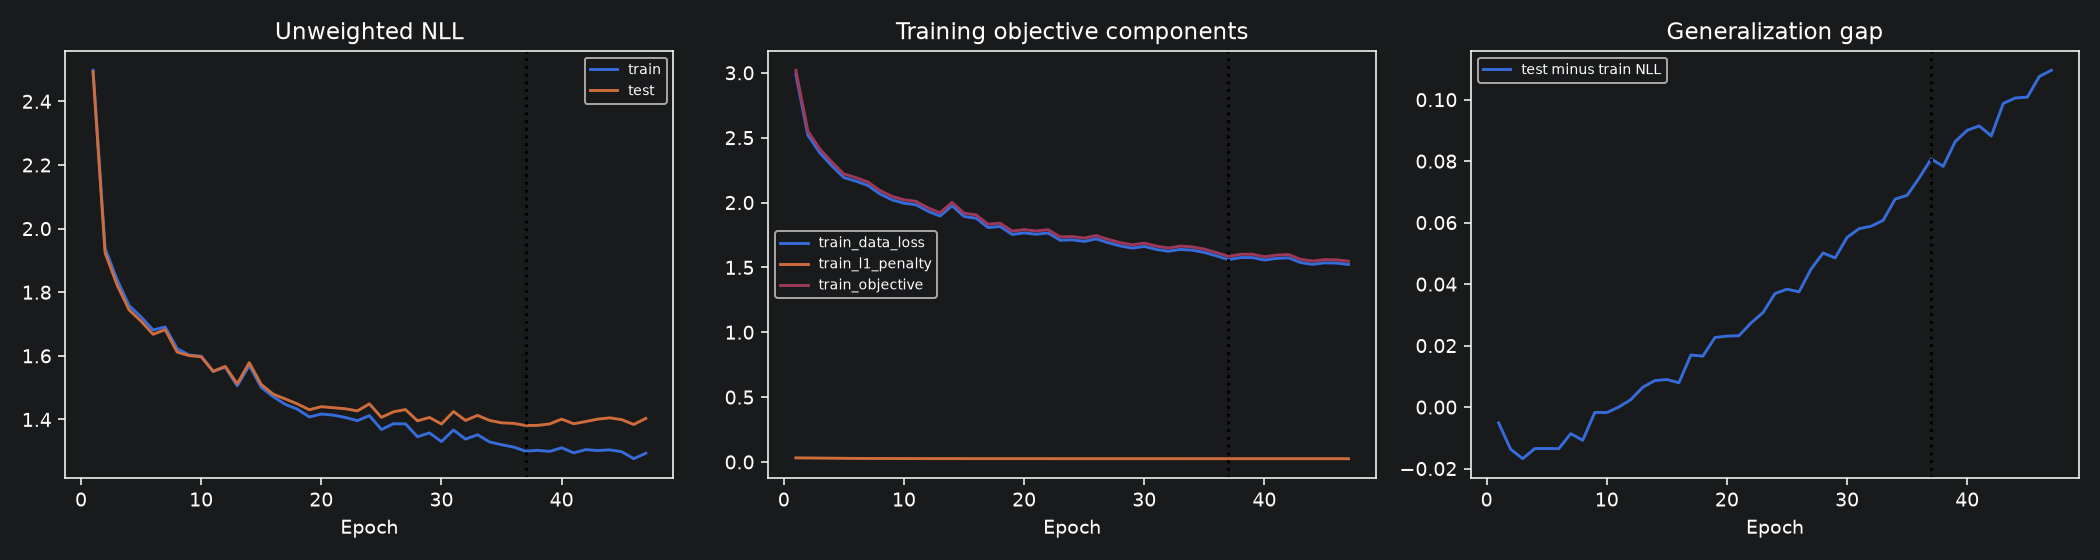

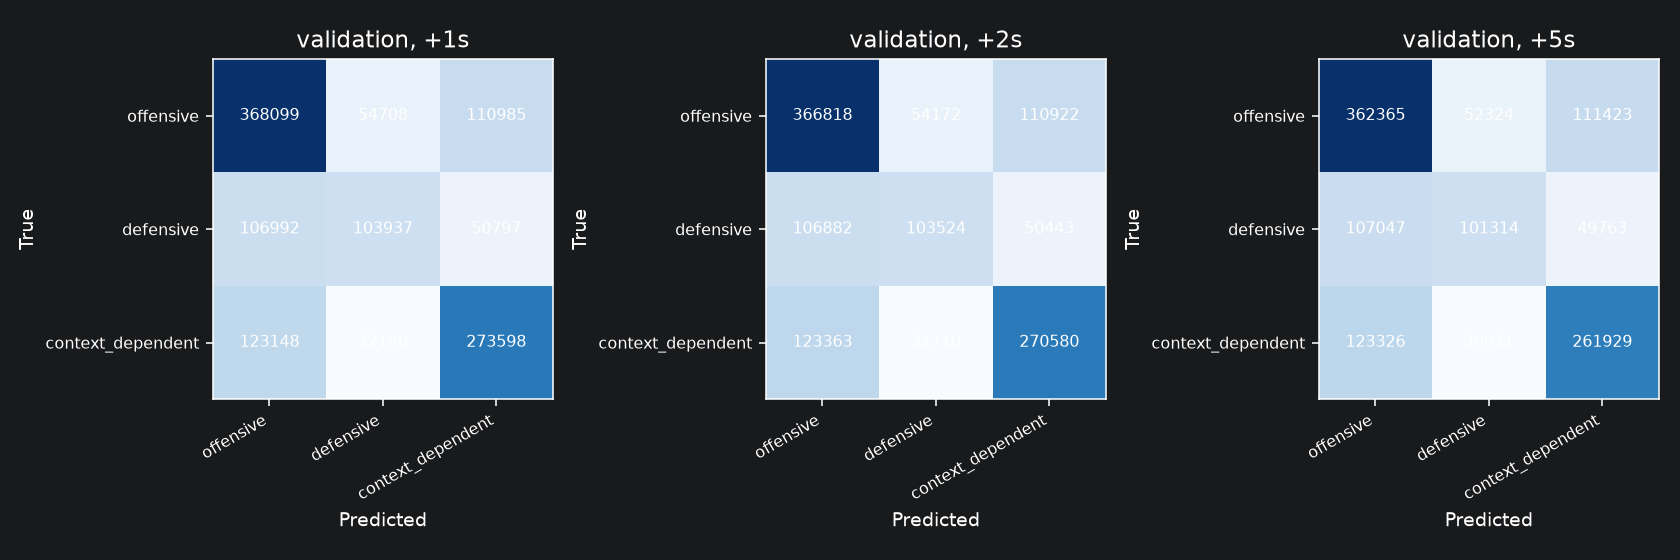

Network weights: C:\Users\theon\Trajectory_Classification\artifacts\nn_duel_skill_intent_forecasting\runs\nn-duel-hierarchical-skill-intent-hgt-s42_20261111T090715798127Z\best.pt
CPU times: total: 15.6 ms
Wall time: 22 ms


In [4]:
%%time
from IPython.display import Image

display(pd.read_csv(RUN / "intent_diagnostics/summary.csv").round(4))
display(Image(filename=str(RUN / "diagnostics/learning_curves.png")))
display(Image(filename=str(RUN / "intent_diagnostics/confusion_intent_head_validation.png")))
print("Network weights:", RUN / "best.pt")


## Use the hierarchical network

`best.pt` contains the HGT/temporal encoder, family head, conditional direction
head, auxiliary intent head, normalization and frozen mappings. Reconstruct with
`make_model(len(saved["classes"]), saved["model_config"], saved["mean"], saved["std"])`,
load `saved["model_state"]` and call `eval()`.

For a normalized `(batch,51,115)` history:

```python
with torch.inference_mode():
    outputs = model(x, return_hierarchy=True)
    family_probabilities = outputs["family_logits"].softmax(-1)       # (batch,3,29)
    direction_probabilities = outputs["direction_logits"].softmax(-1) # (batch,3,4,2)
    skill_probabilities = outputs["skill_log_probs"].exp()           # (batch,3,33)
    joint_skill = skill_probabilities.argmax(-1)
    greedy = model.decode_hierarchy(outputs["family_logits"], outputs["direction_logits"])
```

`joint_skill` is used by the reported original-skill metrics. `greedy` contains
family-first `family_indices`, then `direction_indices` (-1 for a singleton),
and the corresponding original `skill_indices`. These decisions can differ when
a high-probability mirrored family splits its probability between left and right.

The class/family/paired-family/side order is in `saved["skill_hierarchy"]` and the
model configuration. Side order is **left, right**. Intent order is in
`saved["intent_supervision"]["classes"]`. Inputs still contain only the observer's
current skill; no future labels or predicted opponent family are encoder inputs.

The default `model(x)` / MLflow export returns normalized joint original-skill log
probabilities. Softmax remains compatible with the old skill-score interface.
Use the checkpoint factory and `return_hierarchy=True` to access every head.
`return_intent=True` returns the joint skill log probabilities and intent logits.
Training/resume requires the pinned base dataset and v2 label overlay; inference
from checkpoint weights does not read dataset files.
